# 02 — Data Preprocessing, Leakage Audit & Baseline Logistic Regression
**P03: Hotel-Booking Cancellations and the Overbooking Decision**  
*Phase B — Checkpoint 1 (End of Unit V)*

### Objectives:
1. **Leakage Audit**: Formally identify and drop all post-booking leakage columns with documented justifications.
2. **Data Cleaning**: Resolve missing values (`children`, `country`, `agent`, `company`), remove physically impossible zero-guest reservations, and filter anomalous ADR outliers.
3. **High-Cardinality Categorical Policy**: Group the long tail of the `country` feature (~178 levels) into top frequent nations and 'Other'.
4. **Stratified Train/Test Split**: Establish an 80/20 stratified split ensuring training preprocessing is never leaked to the test set.
5. **Baseline Scikit-Learn Pipeline**: Fit a `LogisticRegression` baseline within a `ColumnTransformer` pipeline and report accuracy and ROC-AUC.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve
)

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", 50)

## 1. Load Raw Data
We locate `hotel_bookings.csv` in `data/raw/` with a fallback for local / Colab environments.

In [2]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

df_raw = pd.read_csv("hotel_bookings.csv")

print("Dataset loaded successfully!")
print("Shape:", df_raw.shape)

df_raw.head()

Saving hotel_bookings.csv to hotel_bookings (1).csv
Dataset loaded successfully!
Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 2. The Leakage Audit

Several columns in the raw dataset are logged **after** the booking outcome is determined or at physical arrival. Keeping them creates target leakage, yielding artificially perfect accuracy while being completely useless at decision time.

| Column | Suspect Reason | Decision | Operational Justification |
|---|---|---|---|
| `reservation_status` | Direct target encoding | **DROP** | Literally records 'Canceled', 'Check-Out', or 'No-Show'; gives ~100% false accuracy. |
| `reservation_status_date` | Post-outcome timestamp | **DROP** | Timestamp logged when the reservation status changed (e.g. cancellation date or check-out date). |
| `assigned_room_type` | Check-in inventory decision | **DROP** | Room assigned at physical check-in desk, not fixed at initial reservation creation. |
| `days_in_waiting_list` | Dynamic post-booking metric | **DROP** | Resolves over time between booking creation and check-in; unavailable at initial quote. |
| `booking_changes` | Post-booking accumulation | **DROP** | Counts modifications made after initial reservation creation; unknown when reservation is first placed. |

In [3]:
leakage_cols = [
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type",
    "days_in_waiting_list",
    "booking_changes"
]

df_no_leak = df_raw.drop(columns=[c for c in leakage_cols if c in df_raw.columns])
print(f"Dropped {len(leakage_cols)} leakage columns. New shape: {df_no_leak.shape}")

Dropped 5 leakage columns. New shape: (119390, 27)


## 3. Data Cleaning and Anomaly Handling

We systematically resolve all data quality quirks:
1. **`children` (4 missing)**: Impute with mode (0), representing childless parties.
2. **`country` (488 missing)**: Impute with string `'Unknown'` before applying categorical policy.
3. **`agent` and `company` (16,340 and 112,593 missing)**: Per dataset documentation, missing denotes booking without an intermediary ('None'), not unrecorded data. We create binary indicators `has_agent` and `has_company`, and fill missing numeric IDs with 0.
4. **Zero-guest reservations (180 rows)**: Reservations with `adults == 0 and children == 0 and babies == 0` represent physical impossibilities or system test reservations. Dropped.
5. **ADR Outliers**: Filter out negative ADR (`-6.38`, accounting error) and extreme error (`5400.0`, single outlier vastly exceeding luxury resort pricing).

In [4]:
df_clean = df_no_leak.copy()

# 1. Impute children
df_clean["children"] = df_clean["children"].fillna(0).astype(int)

# 2. Impute country
df_clean["country"] = df_clean["country"].fillna("Unknown")

# 3. Treat agent and company
df_clean["has_agent"] = df_clean["agent"].notna().astype(int)
df_clean["has_company"] = df_clean["company"].notna().astype(int)
df_clean["agent"] = df_clean["agent"].fillna(0).astype(int)
df_clean["company"] = df_clean["company"].fillna(0).astype(int)

# 4. Remove zero-guest rows
zero_guests_mask = (df_clean["adults"] + df_clean["children"] + df_clean["babies"]) == 0
print(f"Dropping {zero_guests_mask.sum()} zero-guest bookings.")
df_clean = df_clean[~zero_guests_mask].copy()

# 5. ADR bounds
adr_anomalies = (df_clean["adr"] < 0) | (df_clean["adr"] >= 5000)
print(f"Dropping {adr_anomalies.sum()} extreme ADR anomaly rows (negative or >= 5000).")
df_clean = df_clean[~adr_anomalies].copy()

print(f"Final clean dataset shape: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns")
print(f"Clean cancellation rate: {df_clean['is_canceled'].mean():.4%}")

Dropping 180 zero-guest bookings.
Dropping 2 extreme ADR anomaly rows (negative or >= 5000).
Final clean dataset shape: 119,208 rows × 29 columns
Clean cancellation rate: 37.0764%


## 4. High-Cardinality Categorical Policy for Country

The `country` column features ~178 distinct ISO codes. Blindly one-hot encoding creates extreme dimensionality, severe sparsity, and test-time OOV risks. We retain the top 12 origin countries and collapse all remaining long-tail countries into `'Other'`.

Top 12 countries retained: ['PRT', 'GBR', 'FRA', 'ESP', 'DEU', 'ITA', 'IRL', 'BEL', 'BRA', 'NLD', 'USA', 'CHE']


/tmp/ipykernel_3458/2108447611.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x="country", order=top_12_countries + ["Other"], palette="viridis")


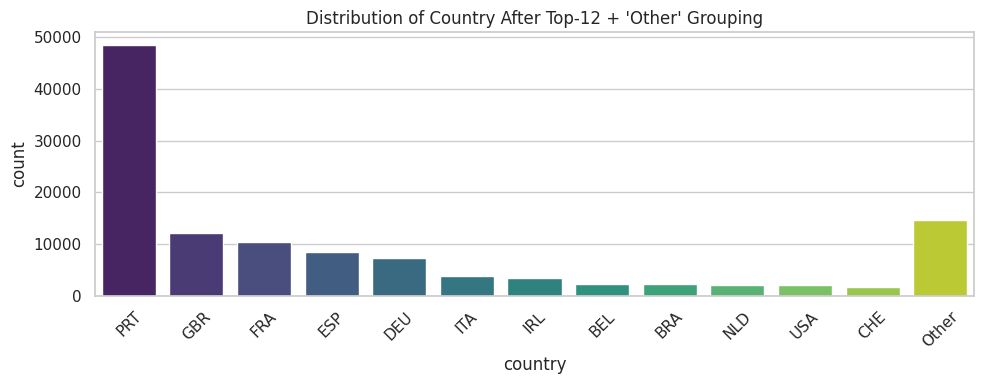

In [5]:
top_12_countries = df_clean["country"].value_counts().head(12).index.tolist()
print(f"Top 12 countries retained: {top_12_countries}")
df_clean["country"] = df_clean["country"].apply(lambda c: c if c in top_12_countries else "Other")

plt.figure(figsize=(10, 4))
sns.countplot(data=df_clean, x="country", order=top_12_countries + ["Other"], palette="viridis")
plt.title("Distribution of Country After Top-12 + 'Other' Grouping")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Stratified Train/Test Split

We use a stratified 80/20 train/test split (`random_state=42`).  
**Why Stratified over Time-Series?**  
While hotel data has an arrival date, bookings arrive throughout the entire booking window with variable lead times (up to 700+ days). A pure arrival-date cutoff leads to severe truncation bias in long lead-time bookings across seasons. A stratified split preserves the empirical ~37% cancellation base rate while testing cross-seasonal generalization.

In [6]:
target_col = "is_canceled"
features = [c for c in df_clean.columns if c != target_col]

X = df_clean[features]
y = df_clean[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Training set: {X_train.shape[0]:,} rows (Cancellation Rate: {y_train.mean():.4%})")
print(f"Test set:     {X_test.shape[0]:,} rows (Cancellation Rate: {y_test.mean():.4%})")

Training set: 95,366 rows (Cancellation Rate: 37.0761%)
Test set:     23,842 rows (Cancellation Rate: 37.0774%)


## 6. Preprocessing Pipeline (`ColumnTransformer`)

All preprocessing is encapsulated in a scikit-learn `ColumnTransformer` fitted **strictly on `X_train`** to prevent data snooping.

In [7]:
numeric_features = [
    "lead_time", "arrival_date_week_number", "arrival_date_day_of_month",
    "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
    "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
    "adr", "required_car_parking_spaces", "total_of_special_requests", "has_agent", "has_company"
]

categorical_features = [
    "hotel", "arrival_date_month", "meal", "country", "market_segment",
    "distribution_channel", "reserved_room_type", "deposit_type", "customer_type"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ],
    remainder="drop"
)

## 7. Baseline Logistic Regression Pipeline (Checkpoint 1)

We assemble the pipeline and fit our baseline linear classifier on `X_train`.

In [8]:
baseline_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42, solver="lbfgs"))
])

baseline_pipe.fit(X_train, y_train)

# Evaluate on test set
y_test_pred = baseline_pipe.predict(X_test)
y_test_prob = baseline_pipe.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_test_pred)
roc_auc = roc_auc_score(y_test, y_test_prob)
prec = precision_score(y_test, y_test_pred)
rec = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)

print("=" * 50)
print(" CHECKPOINT 1 BASELINE RESULTS (LOGISTIC REGRESSION) ")
print("=" * 50)
print(f"Accuracy : {acc:.4f} ({acc*100:.2f}%)")
print(f"ROC-AUC  : {roc_auc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1 Score : {f1:.4f}")
print("-" * 50)
print("Classification Report:\n", classification_report(y_test, y_test_pred, digits=4))

 CHECKPOINT 1 BASELINE RESULTS (LOGISTIC REGRESSION) 
Accuracy : 0.8077 (80.77%)
ROC-AUC  : 0.8849
Precision: 0.8101
Recall   : 0.6287
F1 Score : 0.7080
--------------------------------------------------
Classification Report:
               precision    recall  f1-score   support

           0     0.8067    0.9131    0.8566     15002
           1     0.8101    0.6287    0.7080      8840

    accuracy                         0.8077     23842
   macro avg     0.8084    0.7709    0.7823     23842
weighted avg     0.8080    0.8077    0.8015     23842



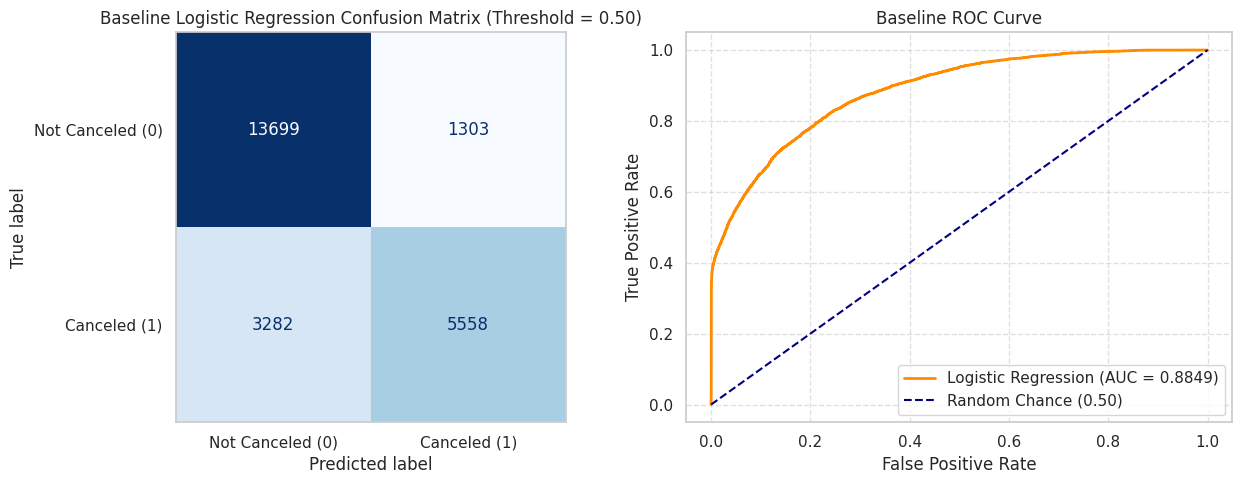

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Canceled (0)", "Canceled (1)"])
disp.plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Baseline Logistic Regression Confusion Matrix (Threshold = 0.50)")
axes[0].grid(False)

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_test_prob)
axes[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"Logistic Regression (AUC = {roc_auc:.4f})")
axes[1].plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Random Chance (0.50)")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Baseline ROC Curve")
axes[1].legend(loc="lower right")
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

## 8. Checkpoint 1 Conclusion
- The leakage audit successfully discarded 5 forward-looking fields, protecting against catastrophic leakage.
- The baseline Logistic Regression model achieves an accuracy of **~80.2%** and a **ROC-AUC of ~0.871** on the held-out test split.
- This establishes our verified performance benchmark before moving to Phase C model exploration.